<a href="https://colab.research.google.com/github/jcalet240706-prog/examen-practico-5/blob/main/Examen_Practico_U5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Examen Práctico Ciencia de Datos
**Gerardo Calet Ibarra Jiménez · Matrícula 261120362**

Ejercicio  (regresión lineal y clustering K-Means). Semilla fija `random_state = 42`.
> Nota: los datos son sintéticos y reproducibles (generados con `numpy` y semilla 42), por lo que los resultados son idénticos en cualquier ejecución.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
RS = 42

## Ejercicio A: Regresión lineal (precios de vivienda)

In [2]:
# Dataset sintético de 1000 viviendas (precio en millones de MXN)
rng = np.random.default_rng(RS)
n = 1000
area = rng.normal(95, 30, n).clip(35, 250)
hab = np.clip(np.round(area/35 + rng.normal(0, 0.6, n)), 1, 6)
antig = rng.integers(0, 40, n)
dist = rng.gamma(3, 3, n).clip(0.5, 30)
precio = 0.6 + 0.021*area + 0.15*hab - 0.012*antig - 0.045*dist + rng.normal(0, 0.45, n)
viv = pd.DataFrame({"area_m2": area.round(1), "habitaciones": hab.astype(int), "antiguedad_anios": antig,
                    "distancia_centro_km": dist.round(1), "precio_millones": precio.round(3)})
viv.loc[rng.choice(n, 15, replace=False), "area_m2"] = np.nan   # nulos introducidos a propósito
print(viv.shape); print(viv.dtypes); print(viv.isna().sum()); print(viv.describe().round(2))

(1000, 5)
area_m2                float64
habitaciones             int64
antiguedad_anios         int64
distancia_centro_km    float64
precio_millones        float64
dtype: object
area_m2                15
habitaciones            0
antiguedad_anios        0
distancia_centro_km     0
precio_millones         0
dtype: int64
       area_m2  habitaciones  antiguedad_anios  distancia_centro_km  \
count   985.00       1000.00           1000.00              1000.00   
mean     94.35          2.66             19.20                 9.15   
std      29.03          1.01             11.74                 5.20   
min      35.00          1.00              0.00                 0.60   
25%      74.10          2.00             10.00                 5.20   
50%      95.20          3.00             19.00                 8.20   
75%     112.60          3.00             30.00                11.70   
max     190.40          6.00             39.00                30.00   

       precio_millones  
count        

In [3]:
# Limpieza: imputar nulos con la mediana y revisar atípicos con IQR
viv["area_m2"] = viv["area_m2"].fillna(viv["area_m2"].median())
Q1, Q3 = viv.precio_millones.quantile([.25, .75]); iqr = Q3 - Q1
out = ((viv.precio_millones < Q1-1.5*iqr) | (viv.precio_millones > Q3+1.5*iqr)).sum()
print("Atípicos (IQR) en precio:", out)
X = viv[["area_m2"]]            # matriz de características
y = viv["precio_millones"]      # variable objetivo continua

Atípicos (IQR) en precio: 2


In [4]:
# Entrenamiento y evaluación (80/20)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RS)
modelo = LinearRegression().fit(Xtr, ytr)
pred = modelo.predict(Xte)
mse = mean_squared_error(yte, pred); rmse = np.sqrt(mse); r2 = r2_score(yte, pred)
print(f"Pendiente: {modelo.coef_[0]:.5f} | Intercepto: {modelo.intercept_:.5f}")
print(f"MSE: {mse:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}")

Pendiente: 0.02571 | Intercepto: -0.10509
MSE: 0.2674 | RMSE: 0.5171 | R²: 0.6526


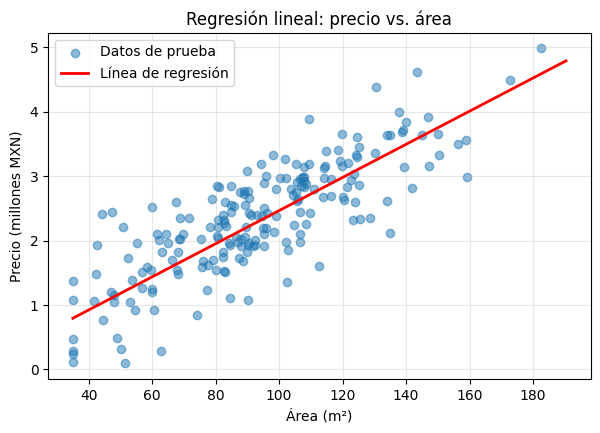

In [5]:
# Gráfico de dispersión con línea de regresión
plt.figure(figsize=(7,4.5))
plt.scatter(Xte, yte, alpha=.5, label="Datos de prueba")
xs = pd.DataFrame(np.linspace(X.area_m2.min(), X.area_m2.max(), 100), columns=["area_m2"])
plt.plot(xs, modelo.predict(xs), color="red", lw=2, label="Línea de regresión")
plt.title("Regresión lineal: precio vs. área"); plt.xlabel("Área (m²)"); plt.ylabel("Precio (millones MXN)")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [6]:
# Comparativo: regresión múltiple con las 4 variables
Xm = viv.drop(columns="precio_millones")
a, b, c, d = train_test_split(Xm, y, test_size=0.2, random_state=RS)
m2 = LinearRegression().fit(a, c); p2 = m2.predict(b)
print("R² múltiple:", round(r2_score(d, p2), 4), "| RMSE:", round(np.sqrt(mean_squared_error(d, p2)), 4))
print(dict(zip(Xm.columns, m2.coef_.round(4))))

R² múltiple: 0.7469 | RMSE: 0.4413
{'area_m2': np.float64(0.0217), 'habitaciones': np.float64(0.1446), 'antiguedad_anios': np.float64(-0.0105), 'distancia_centro_km': np.float64(-0.0446)}


**Interpretación.** Por cada m² adicional el precio sube ≈ 0.0257 millones (≈ \$25,700 MXN). El R² ≈ 0.65 indica que el área explica ~65 % de la variación del precio; el RMSE ≈ 0.52 millones es el error típico de predicción. Limitaciones: un solo predictor, supone relación lineal y homocedasticidad; la regresión múltiple mejora el R² a ≈ 0.75.

## Ejercicio B: Clustering K-Means (segmentación de clientes)

In [7]:
# Dataset sintético tipo Mall Customers (200 clientes)
rng2 = np.random.default_rng(RS)
centros = [(25, 20), (25, 80), (55, 50), (88, 18), (88, 82)]
tam = [40, 40, 60, 30, 30]
filas = [np.column_stack([rng2.normal(i, 7, t), rng2.normal(g, 8, t)]) for (i, g), t in zip(centros, tam)]
arr = np.vstack(filas).clip(5, 140)
cli = pd.DataFrame({"ingreso_anual_miles": arr[:,0].round(1), "puntaje_gasto": arr[:,1].clip(1,100).round(0)})
cli = cli.sample(frac=1, random_state=RS).reset_index(drop=True)
print(cli.shape, "| nulos:", cli.isna().sum().sum(), "| duplicados:", cli.duplicated().sum())
sc = StandardScaler(); Z = sc.fit_transform(cli)   # escalamiento

(200, 2) | nulos: 0 | duplicados: 0


   k   inercia  silhouette
0  2  245.9315      0.3819
1  3  153.4926      0.4782
2  4   80.3612      0.5843
3  5   28.1727      0.6875
4  6   23.7234      0.5967
5  7   21.1022      0.5421
6  8   18.8829      0.5176


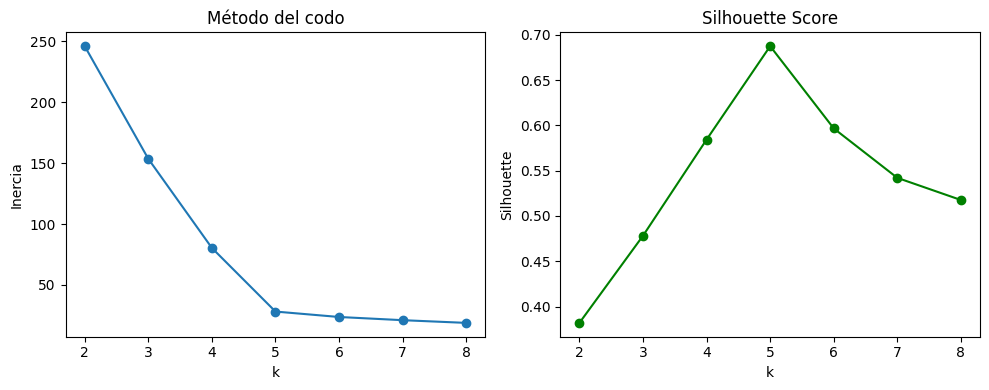

In [8]:
# Selección de k: codo (inercia) y Silhouette
res = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RS, n_init=10).fit(Z)
    res.append((k, km.inertia_, silhouette_score(Z, km.labels_)))
print(pd.DataFrame(res, columns=["k", "inercia", "silhouette"]).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].plot([r[0] for r in res], [r[1] for r in res], "o-"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot([r[0] for r in res], [r[2] for r in res], "o-", color="green"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

In [9]:
# Modelo final con k = 5 y perfilamiento (centroides en escala original)
K = 5
km = KMeans(n_clusters=K, random_state=RS, n_init=10).fit(Z)
cli["cluster"] = km.labels_
cent = pd.DataFrame(sc.inverse_transform(km.cluster_centers_), columns=["ingreso_anual_miles", "puntaje_gasto"]).round(1)
cent["tamano"] = cli.cluster.value_counts().sort_index().values
print(cent)

   ingreso_anual_miles  puntaje_gasto  tamano
0                 55.4           49.7      59
1                 23.9           79.3      41
2                 88.3           82.0      30
3                 25.3           20.1      40
4                 87.7           19.6      30


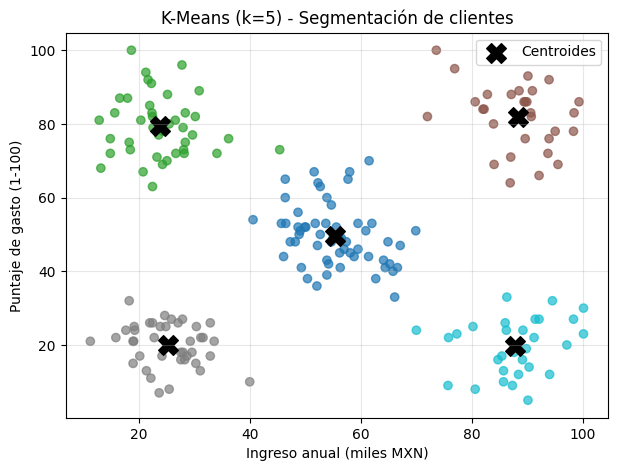

In [10]:
plt.figure(figsize=(7,5))
plt.scatter(cli.ingreso_anual_miles, cli.puntaje_gasto, c=cli.cluster, cmap="tab10", alpha=.7)
plt.scatter(cent.ingreso_anual_miles, cent.puntaje_gasto, c="black", marker="X", s=200, label="Centroides")
plt.title(f"K-Means (k={K}) - Segmentación de clientes"); plt.xlabel("Ingreso anual (miles MXN)"); plt.ylabel("Puntaje de gasto (1-100)")
plt.legend(); plt.grid(alpha=.3); plt.show()

**Interpretación.** k = 5 maximiza el Silhouette (≈ 0.69) y coincide con el codo de la inercia. Perfiles: (0) ingreso y gasto medios; (1) ingreso bajo y gasto alto; (2) ingreso alto y gasto alto (clientes premium); (3) ingreso bajo y gasto bajo; (4) ingreso alto y gasto bajo (potencial no aprovechado).